# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [9]:
from dataclasses import dataclass
import random
import numpy as np
import matplotlib.pyplot as plt

RANKS = ["2","3","4","5","6","7","8","9","10","J","Q","K","A"]
SUITS = ["Clubs","Diamonds","Hearts","Spades"]

@dataclass(frozen=True)
class Card:
    rank: str
    suit: str = ""
    is_plastic: bool = False

    @property
    def value(self):
        if self.is_plastic:
            return 0
        if self.rank == "A":
            return 11
        if self.rank in ("J","Q","K"):
            return 10
        return int(self.rank)

    @property
    def count_value(self):
        if self.is_plastic:
            return 0
        if self.rank in ("2","3","4","5","6"):
            return 1
        if self.rank in ("7","8","9"):
            return 0
        return -1

    def __str__(self):
        return "plastic cut card" if self.is_plastic else f"{self.rank} of {self.suit}"

class Deck:
    def __init__(self, num_decks=6,rng=None):
        if num_decks < 1:
            raise ValueError("num_decks must be at least 1")
        self.num_decks = num_decks
        self.rng = rng or random.Random()
        self.cards = []
        self.cut_card_drawn = False
        self.shuffle()

    def shuffle(self):
        self.cards = [Card(rank,suit) for _ in range(self.num_decks)
                     for suit in SUITS for rank in RANKS]
        self.rng.shuffle(self.cards)
        total = len(self.cards)
        cards_before_cut = self.rng.randint(int(total * 0.70), int(total * 0.85))
        cut_position = max(0, total - cards_before_cut - 1)
        self.cards.insert(cut_position, Card("Plastic", is_plastic = True))
        self.cut_card_drawn = False
        
    def draw(self):
        while self.cards:
            card = self.cards.pop()
            if card.is_plastic:
                self.cut_card_drawn = True
                continue
            return card
        self.shuffle()
        return self.draw()
    
    def __len__(self):
        return sum(not card.is_plastic for card in self.cards)

shoe = Deck(num_decks = 6, rng = random.Random(7))
print(f"Six-deck shoe contains {6*52} playable cards plus one plastic cut card.")
print("Example card:", shoe.draw())

Six-deck shoe contains 312 playable cards plus one plastic cut card.
Example card: J of Clubs


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [10]:
class Hand:
    def __init__(self,cards=None):
        self.cards = list(cards) if cards else []

    def add_card(self, card):
        pass

    @property
    def value(self):
        pass

    @property
    def is_soft(self):
        pass

    @property
    def is_bust(self):
        pass

    @property
    def is_blackjack(self):
        pass

class Player:
    def __init__(self,name,chips=500,bet_size=10):
        self.name = name
        self.chips = float(chips)
        self.bet_size = float(bet_size)
        self.hand = Hand()
        self.current_bet = 0.0

    def begin_round(self):
        pass

    def choose_action(self, game):
        pass

class Dealer:
    def __init__(self):
        self.hand = Hand()

    def should_hit(self):
        pass

class BlackjackGame:
    def __init__(self,players,num_decks=6,seed=None):
        self.players = list(players)
        self.deck = Deck(num_decks = num_decks)
        self.dealer = Dealer()

    def play_round(self, verbose = False):
        pass

    def play(self, n_rounds=1, verbose = True):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [11]:
class Hand:
    def __init__(self, cards = None):
        self.cards = list(cards) if cards else []

    def add_card(self,card):
        self.cards.append(card)

    @property
    def value(self):
        total = sum(1 if card.rank == "A" else card.value for card in self.cards)
        if any(card.rank == "A" for card in self.cards) and total + 10 <= 21:
            total += 10
        return total

    @property
    def is_soft(self):
        low_total = sum(1 if card.rank == "A" else card.value for card in self.cards)
        return any(card.rank == "A" for card in self.cards) and low_total + 10 <= 21

    @property
    def is_bust(self):
        return self.value > 21

    @property
    def is_blackjack(self):
        return len(self.cards) == 2 and self.value == 21

    def __str__(self):
        return ", ".join(str(card) for card in self.cards) + f" (value {self.value})"

class Player:
    def __init__(self, name, chips=500, bet_size = 10):
        self.name = name
        self.chips = float(chips)
        self.bet_size = float(bet_size)
        self.hand = Hand()
        self.current_bet = 0.0
        self.last_result = ""

    def begin_round(self):
        self.hand = Hand()
        self.current_bet = min(self.bet_size, self.chips)
        self.chips -= self.current_bet
        self.last_result = ""

    def choose_action(self,game):
        return "hit" if self.hand.value < 17 else "stand"

class DealerStylePlayer(Player):
    def choose_action(self,game):
        return "hit" if self.hand.value < 17 else "stand"

class HumanPlayer(Player):
    def choose_action(self,game):
        while True:
            choice = input(f"{self.name}: hand {self.hand.value}. Hit or stand? ").strip().lower()
            if choice in ("hit","h"):
                return "hit"
            if choice in ("stand","s"):
                return "stand"
            print("Enter 'hit' or 'stand'.")

class Dealer:
    def __init__(self):
        self.hand = Hand()

    def should_hit(self):
        return self.hand.value < 17


class BlackjackGame:
    def __init__(self, players, num_decks=6, seed=None):
        self.rng = random.Random(seed)
        self.deck = Deck(num_decks=num_decks, rng=self.rng)
        self.players = list(players)
        self.dealer = Dealer()
        self.running_count = 0
        self.round_number = 0
        self.history = []

    def _draw(self, visible=True):
        card = self.deck.draw()
        if visible:
            self.running_count += card.count_value
        return card

    def _settle(self, player):
        bet = player.current_bet
        player_natural = player.hand.is_blackjack
        dealer_natural = self.dealer.hand.is_blackjack

        if player.hand.is_bust:
            player.last_result = "bust / loss"
        elif player_natural and dealer_natural:
            player.chips += bet
            player.last_result = "push (both blackjack)"
        elif dealer_natural:
            player.last_result = "loss (dealer blackjack)"
        elif player_natural:
            player.chips += 2.5 * bet
            player.last_result = "blackjack win"
        elif self.dealer.hand.is_bust or player.hand.value > self.dealer.hand.value:
            player.chips += 2 * bet
            player.last_result = "win"
        elif player.hand.value == self.dealer.hand.value:
            player.chips += bet
            player.last_result = "push"
        else:
            player.last_result = "loss"

    def play_round(self, verbose=False):
        if self.deck.cut_card_drawn:
            self.deck.shuffle()
            self.running_count = 0
            if verbose:
                print("Cut card was reached; the shoe was shuffled before this round.")

        active = [player for player in self.players if player.chips > 0]
        if not active:
            return {}

        self.round_number += 1
        self.dealer.hand = Hand()
        for player in active:
            player.begin_round()

        for deal_index in range(2):
            for player in active:
                player.hand.add_card(self._draw(visible=True))
            self.dealer.hand.add_card(self._draw(visible=(deal_index == 0)))

        if verbose:
            print(f"\nRound {self.round_number} | running count: {self.running_count}")
            print(f"Dealer shows {self.dealer.hand.cards[0]} and one hidden card.")
            for player in active:
                print(f"{player.name}: {player.hand}")

        for player in active:
            if player.hand.is_blackjack:
                continue
            while not player.hand.is_bust:
                action = player.choose_action(self)
                if action != "hit":
                    break
                card = self._draw(visible=True)
                player.hand.add_card(card)
                if verbose:
                    print(f"{player.name} hits: {card}; hand value {player.hand.value}")

        if any(not player.hand.is_bust for player in active):
            while self.dealer.should_hit():
                card = self._draw(visible=True)
                self.dealer.hand.add_card(card)
                if verbose:
                    print(f"Dealer hits: {card}; hand value {self.dealer.hand.value}")

        if len(self.dealer.hand.cards) > 1:
            self.running_count += self.dealer.hand.cards[1].count_value

        for player in active:
            self._settle(player)

        if verbose:
            print("Dealer hand:", self.dealer.hand)
            for player in active:
                print(f"{player.name}: {player.last_result}; chips = {player.chips:.2f}")
            print("Running count after the cards are revealed:", self.running_count)

        round_result = {player.name: {"chips": player.chips, "result": player.last_result}
                        for player in active}
        self.history.append(round_result)

        if self.deck.cut_card_drawn:
            self.deck.shuffle()
            self.running_count = 0
            if verbose:
                print("Cut card was dealt; the shoe will be fresh for the next round.")
        return round_result

    def play(self, n_rounds=1, verbose=True):
        for _ in range(n_rounds):
            if not any(player.chips > 0 for player in self.players):
                break
            self.play_round(verbose=verbose)

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [12]:
demo_players = [DealerStylePlayer(f"Computer {i}", chips=200, bet_size = 10) for i in range(1,4)]
demo_game = BlackjackGame(demo_players, num_decks = 6, seed=42)
demo_game.play(n_rounds=5,verbose=True)


Round 1 | running count: -3
Dealer shows 10 of Diamonds and one hidden card.
Computer 1: 7 of Clubs, Q of Clubs (value 17)
Computer 2: A of Clubs, 8 of Diamonds (value 19)
Computer 3: Q of Hearts, 2 of Clubs (value 12)
Computer 3 hits: 7 of Spades; hand value 19
Dealer hand: 10 of Diamonds, 8 of Diamonds (value 18)
Computer 1: loss; chips = 190.00
Computer 2: win; chips = 210.00
Computer 3: win; chips = 210.00
Running count after the cards are revealed: -3

Round 2 | running count: -1
Dealer shows 4 of Diamonds and one hidden card.
Computer 1: 5 of Spades, 10 of Spades (value 15)
Computer 2: 10 of Clubs, 9 of Clubs (value 19)
Computer 3: 5 of Diamonds, 4 of Diamonds (value 9)
Computer 1 hits: 2 of Diamonds; hand value 17
Computer 3 hits: 3 of Hearts; hand value 12
Computer 3 hits: Q of Spades; hand value 22
Dealer hits: 7 of Spades; hand value 21
Dealer hand: 4 of Diamonds, K of Spades, 7 of Spades (value 21)
Computer 1: loss; chips = 180.00
Computer 2: loss; chips = 200.00
Computer 3

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [13]:
class CountThresholdPlayer(Player):
    def __init__(self,name,chips=500,bet_size=10,threshold=0):
        super().__init__(name,chips,bet_size)
        self.threshold = threshold

    def choose_action(self,game):
        total = self.hand.value
        if total < 12:
            return "hit"
        if total >= 17:
            return "stand"
        if self.hand.is_soft:
            return "hit" if total < 18 else "stand"
        return "hit" if game.running_count < self.threshold else "stand"

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [15]:
starting_chips = 500
threshold = 0
count_player = CountThresholdPlayer("Count strategy", chips=starting_chips, bet_size=10, threshold=threshold)
other_players = [DealerStylePlayer(f"Computer {i}", chips = starting_chips, bet_size = 10) for i in range(1,4)]
scenario_game = BlackjackGame([count_player] + other_players, num_decks=6, seed=2026)

for _ in range(50):
    if count_player.chips <= 0:
        break
    scenario_game.play_round(verbose=False)

net_winnings = count_player.chips - starting_chips
print("Rounds played:", scenario_game.round_number)
print("Ending chips:", round(count_player.chips,2))
print("Net winnings:", round(net_winnings,2))

Rounds played: 50
Ending chips: 510.0
Net winnings: 10.0


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Average net winnings per round: -0.698
Standard deviation of net winnings: 73.32
Probability of net winning: 0.28
Probability of net losing: 0.72
Probability of breaking even: 0.0


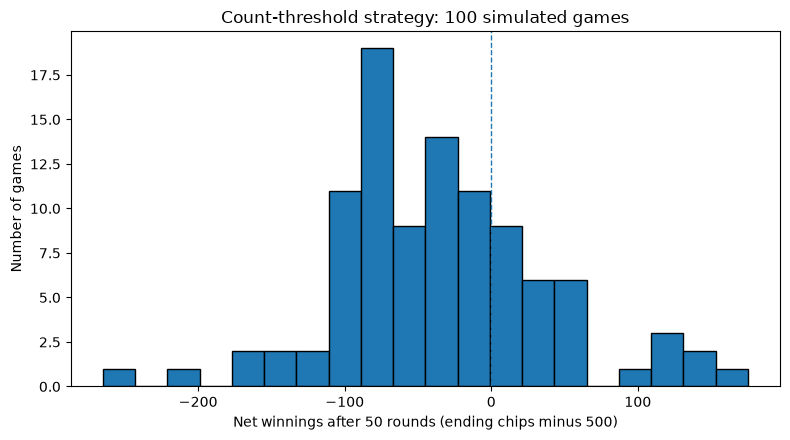

In [18]:
def run_counting_experiment(threshold, n_games=100, n_rounds=50,
                            starting_chips=500, bet_size=10, seed=1000):
    ending_chips = []
    rounds_played = []

    for game_index in range(n_games):
        strategy_player = CountThresholdPlayer(
            "Count strategy",
            chips=starting_chips,
            bet_size=bet_size,
            threshold=threshold
        )

        opponents = [
            DealerStylePlayer(
                f"Computer {i}",
                chips=starting_chips,
                bet_size=bet_size
            )
            for i in range(1, 4)
        ]

        game = BlackjackGame(
            [strategy_player] + opponents,
            num_decks=6,
            seed=seed + game_index
        )

        for _ in range(n_rounds):
            if strategy_player.chips <= 0:
                break
            game.play_round(verbose=False)

        ending_chips.append(strategy_player.chips)
        rounds_played.append(game.round_number)

    ending_chips = np.asarray(ending_chips, dtype=float)
    net = ending_chips - starting_chips
    actual_rounds = np.asarray(rounds_played, dtype=float)

    profit_per_round = np.divide(
        net,
        actual_rounds,
        out=np.zeros_like(net),
        where=actual_rounds > 0
    )

    return {
        "threshold": threshold,
        "ending_chips": ending_chips,
        "net_winnings": net,
        "rounds_played": actual_rounds,
        "average_net_per_round": float(np.mean(profit_per_round)),
        "sd_net_winnings": float(np.std(net, ddof=1)),
        "prob_net_win": float(np.mean(net > 0)),
        "prob_net_loss": float(np.mean(net < 0)),
        "prob_tie": float(np.mean(net == 0)),
    }
experiment = run_counting_experiment(threshold=0)
net = experiment["net_winnings"]
print("Average net winnings per round:", round(experiment["average_net_per_round"], 3))
print("Standard deviation of net winnings:", round(experiment["sd_net_winnings"], 2))
print("Probability of net winning:", round(experiment["prob_net_win"], 3))
print("Probability of net losing:", round(experiment["prob_net_loss"], 3))
print("Probability of breaking even:", round(experiment["prob_tie"], 3))

plt.figure(figsize=(8, 4.5))
plt.hist(net, bins=20, edgecolor="black")
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Net winnings after 50 rounds (ending chips minus 500)")
plt.ylabel("Number of games")
plt.title("Count-threshold strategy: 100 simulated games")
plt.tight_layout()
plt.show()

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

 Threshold   Avg net/round       SD net     P(win)    P(loss)
        -5          -0.665        75.17      0.320      0.670
        -2          -0.605        74.31      0.290      0.680
         0          -0.698        73.32      0.280      0.720
         2          -0.561        68.56      0.300      0.670
         5          -0.470        68.30      0.410      0.570


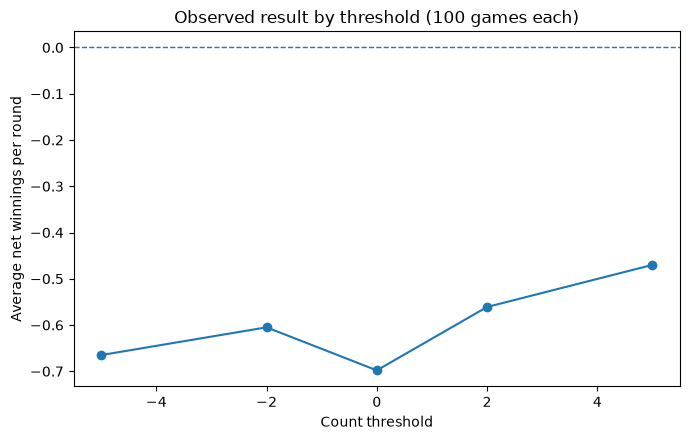

Best observed threshold in this run: 5
This is the best result among the tested thresholds for these simulations; results vary with the shoe order.


In [19]:
threshold_results = [run_counting_experiment(threshold=t, seed=1000) for t in [-5, -2, 0, 2, 5]]
print(f"{'Threshold':>10} {'Avg net/round':>15} {'SD net':>12} {'P(win)':>10} {'P(loss)':>10}")
for result in threshold_results:
    print(f"{result['threshold']:>10} {result['average_net_per_round']:>15.3f} "
          f"{result['sd_net_winnings']:>12.2f} {result['prob_net_win']:>10.3f} "
          f"{result['prob_net_loss']:>10.3f}")

best = max(threshold_results, key=lambda r: r["average_net_per_round"])
plt.figure(figsize=(7, 4.5))
plt.plot([r["threshold"] for r in threshold_results],
         [r["average_net_per_round"] for r in threshold_results], marker="o")
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Count threshold")
plt.ylabel("Average net winnings per round")
plt.title("Observed result by threshold (100 games each)")
plt.tight_layout()
plt.show()
print("Best observed threshold in this run:", best["threshold"])
print("This is the best result among the tested thresholds for these simulations; results vary with the shoe order.")

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

Strategy comparison, 100 games of up to 50 rounds each
Count-threshold: average net/round = -0.648, SD = 78.49, P(win) = 0.330, P(loss) = 0.670
Basic-strategy approximation: average net/round = -0.763, SD = 70.32, P(win) = 0.240, P(loss) = 0.760


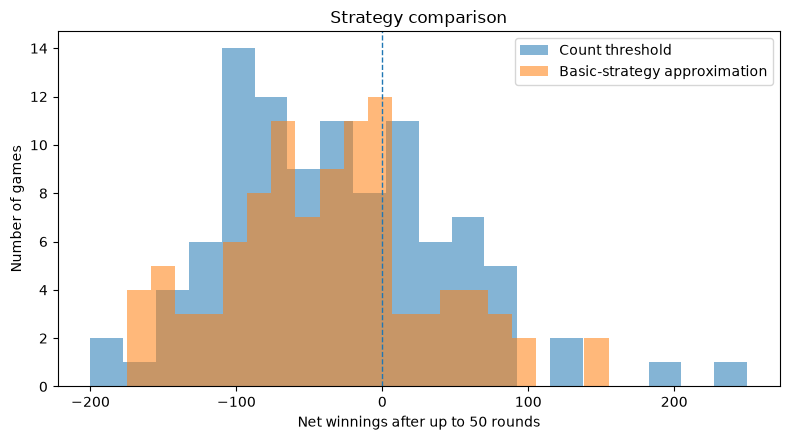

In [22]:
class BasicStrategyPlayer(Player):
    def choose_actions(self, game):
        total = self.hand.value
        if total >= 17:
            return "stand"
        if total <= 11:
            return "hit"

        dealer_up = game.dealer.hand.cards[0]
        dealer_value = dealer_up.value

        if self.hand.is_soft:
            if total < 18:
                return "hit"
            if total == 18 and dealer_value in (9,10,11):
                return "hit"
            return "stand"

def run_player_type_experiment(player_type, n_games=100, n_rounds=50,
                               starting_chips=500, bet_size=10, seed=3000):
    ending_chips = []
    rounds_played = []
    for game_index in range(n_games):
        if player_type == "count":
            strategy_player = CountThresholdPlayer("Strategy", starting_chips, bet_size, threshold=0)
        elif player_type == "basic":
            strategy_player = BasicStrategyPlayer("Strategy", starting_chips, bet_size)
        else:
            raise ValueError("player_type must be 'count' or 'basic'")

        opponents = [DealerStylePlayer(f"Computer {i}", starting_chips, bet_size) for i in range(1, 4)]
        game = BlackjackGame([strategy_player] + opponents, num_decks=6, seed=seed + game_index)
        for _ in range(n_rounds):
            if strategy_player.chips <= 0:
                break
            game.play_round(verbose=False)
        ending_chips.append(strategy_player.chips)
        rounds_played.append(game.round_number)

    ending_chips = np.asarray(ending_chips, dtype=float)
    net = ending_chips - starting_chips
    turns = np.asarray(rounds_played, dtype=float)
    per_round = np.divide(net, turns, out=np.zeros_like(net), where=turns > 0)
    return {
        "net_winnings": net,
        "average_net_per_round": float(np.mean(per_round)),
        "sd_net_winnings": float(np.std(net, ddof=1)),
        "prob_net_win": float(np.mean(net > 0)),
        "prob_net_loss": float(np.mean(net < 0)),
    }


count_result = run_player_type_experiment("count")
basic_result = run_player_type_experiment("basic")
print("Strategy comparison, 100 games of up to 50 rounds each")
print(f"Count-threshold: average net/round = {count_result['average_net_per_round']:.3f}, "
      f"SD = {count_result['sd_net_winnings']:.2f}, P(win) = {count_result['prob_net_win']:.3f}, "
      f"P(loss) = {count_result['prob_net_loss']:.3f}")
print(f"Basic-strategy approximation: average net/round = {basic_result['average_net_per_round']:.3f}, "
      f"SD = {basic_result['sd_net_winnings']:.2f}, P(win) = {basic_result['prob_net_win']:.3f}, "
      f"P(loss) = {basic_result['prob_net_loss']:.3f}")

plt.figure(figsize=(8, 4.5))
plt.hist(count_result["net_winnings"], bins=20, alpha=0.55, label="Count threshold")
plt.hist(basic_result["net_winnings"], bins=20, alpha=0.55, label="Basic-strategy approximation")
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Net winnings after up to 50 rounds")
plt.ylabel("Number of games")
plt.title("Strategy comparison")
plt.legend()
plt.tight_layout()
plt.show()